# Explaining House Values in California (OLS Regression)

What drives median house values across California's census block groups, and how much does *location* add
beyond income and housing characteristics? This notebook builds an OLS model on the 1990 California census
housing data (20,640 block groups), with a focus on careful data preparation and diagnostics.

**Methods:** correlation and spatial EDA · outlier treatment (winsorisation at the 1st/99th percentiles, thresholds
learnt on the training set only) · skewness-driven log transforms · feature engineering of geographic distance
variables · standardisation · OLS · RMSE/R² on a held-out test set · residual diagnostics · ablation tests.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from scipy import stats

warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True)

## 1. Data and train/test split

The dataset is downloaded directly from scikit-learn, so no data files are needed. Target: `MedHouseVal`, the
median house value in \$100,000s (capped at \$500,000). An 80/20 split is made before any cleaning so that all
cleaning thresholds are learnt from the training data only.

In [2]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()
print(f"Dataset shape: {df.shape}")
print(df.head())

X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"\nTraining set: {X_train.shape[0]} samples")
print(f"Test set:     {X_test.shape[0]} samples")

Dataset shape: (20640, 9)
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

Training set: 16512 samples
Test set:     4128 samples


## 2. Exploratory analysis

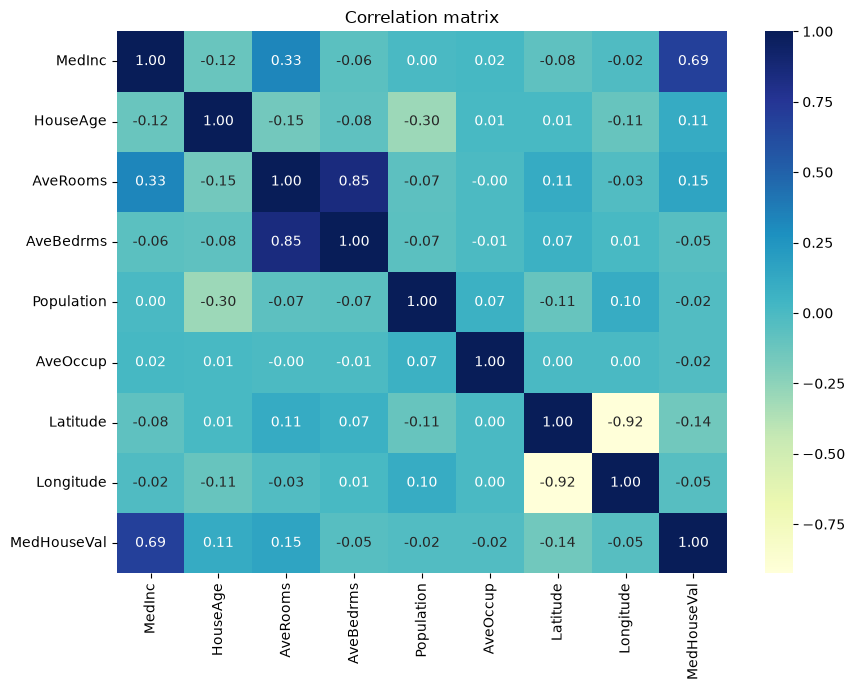

In [3]:
# Correlation matrix: how strongly each feature moves with every other feature
co_mtx = df.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(data=co_mtx, cmap="YlGnBu", annot=True, fmt=".2f")
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig("figures/correlation_heatmap.png", dpi=150)
plt.show()

Median income is by far the strongest positive correlate of house value (0.69), followed by average rooms
(0.15). Latitude is the most negative (−0.14): values tend to fall further north.

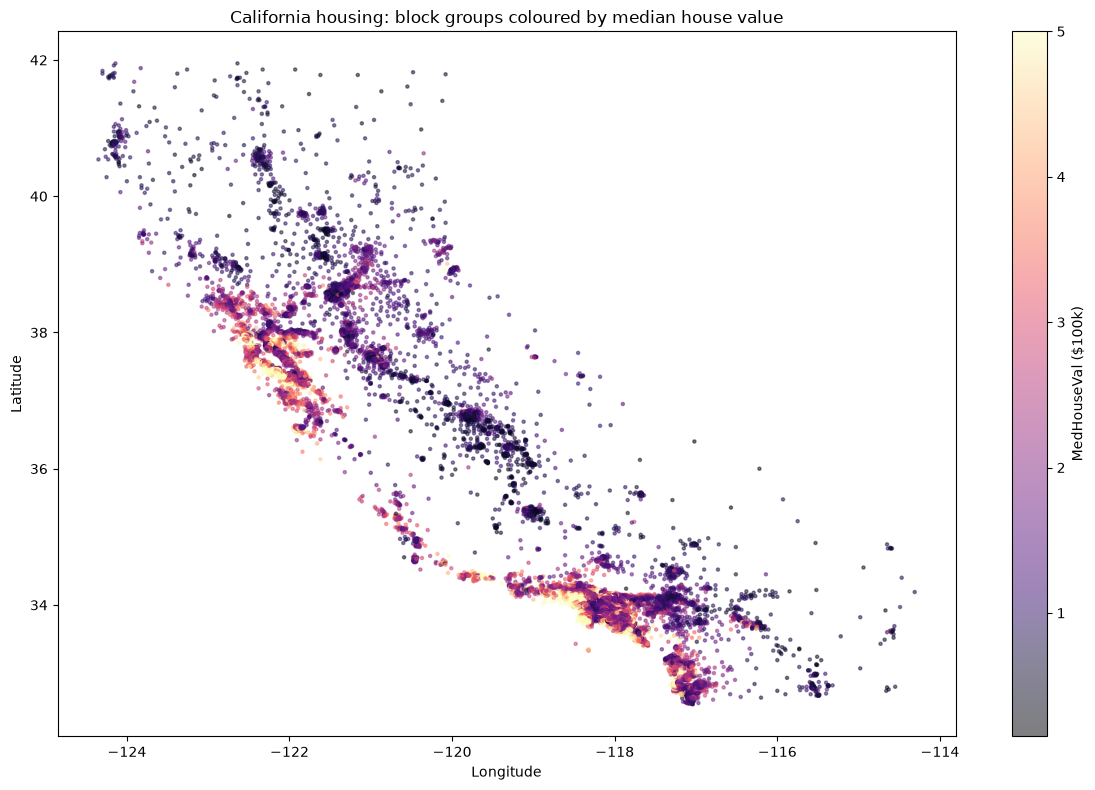

In [4]:
# Map of block groups coloured by house value
plt.figure(figsize=(12, 8))
scatter = plt.scatter(df["Longitude"], df["Latitude"], c=df["MedHouseVal"], cmap="magma", s=5, alpha=0.5)
plt.colorbar(scatter, label="MedHouseVal ($100k)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("California housing: block groups coloured by median house value")
plt.tight_layout()
plt.savefig("figures/geographic_scatter.png", dpi=150)
plt.show()

The highest values cluster along the coast, densest around San Francisco and Los Angeles; inland areas are
markedly cheaper. This motivates the distance-based features in section 4.

In [5]:
# Descriptive statistics, train vs test: the split preserves the distributions
print("Training set")
print(X_train.describe().T.round(2))
print("\nTest set")
print(X_test.describe().T.round(2))

Training set
              count     mean      std     min     25%      50%      75%  \
MedInc      16512.0     3.88     1.90    0.50    2.57     3.55     4.77   
HouseAge    16512.0    28.61    12.60    1.00   18.00    29.00    37.00   
AveRooms    16512.0     5.44     2.39    0.89    4.45     5.24     6.06   
AveBedrms   16512.0     1.10     0.43    0.33    1.01     1.05     1.10   
Population  16512.0  1426.45  1137.06    3.00  789.00  1167.00  1726.00   
AveOccup    16512.0     3.10    11.58    0.69    2.43     2.82     3.28   
Latitude    16512.0    35.64     2.14   32.55   33.93    34.26    37.72   
Longitude   16512.0  -119.58     2.01 -124.35 -121.81  -118.51  -118.01   

                 max  
MedInc         15.00  
HouseAge       52.00  
AveRooms      141.91  
AveBedrms      25.64  
Population  35682.00  
AveOccup     1243.33  
Latitude       41.95  
Longitude    -114.31  

Test set
             count     mean      std     min     25%      50%      75%  \
MedInc      4128.0  

## 3. Data preparation

There are no missing values, so no imputation or deletion is needed. Several per-household averages have extreme
upper tails (e.g. block groups that are mostly vacation homes). These are **winsorised** at the 1st and 99th
percentiles of the *training* set, and the same thresholds are applied to the test set. Winsorising keeps every
observation (unlike trimming) while limiting the influence of extreme values.

In [6]:
print("Missing values (train):", int(X_train.isnull().sum().sum()))
print("Missing values (test): ", int(X_test.isnull().sum().sum()))

# Inspect the tails of each feature in the training set
for col in X_train:
    print(f"\n{col}")
    print(X_train[col].describe(percentiles=[0.01, 0.05, 0.95, 0.99]).to_string())

Missing values (train): 0
Missing values (test):  0

MedInc
count    16512.000000
mean         3.880754
std          1.904294
min          0.499900
1%           1.066898
5%           1.599460
95%          7.310800
99%         10.576902
max         15.000100

HouseAge
count    16512.000000
mean        28.608285
std         12.602499
min          1.000000
1%           4.000000
5%           8.000000
95%         52.000000
99%         52.000000
max         52.000000

AveRooms
count    16512.000000
mean         5.435235
std          2.387375
min          0.888889
1%           2.578195
5%           3.438549
95%          7.645946
99%         10.318432
max        141.909091

AveBedrms
count    16512.000000
mean         1.096685
std          0.433215
min          0.333333
1%           0.871161
5%           0.939394
95%          1.276685
99%          2.116536
max         25.636364

Population
count    16512.000000
mean      1426.453004
std       1137.056380
min          3.000000
1%          88.11

In [7]:
# AveRooms, AveBedrms, AveOccup and Population have extreme outliers beyond the 99th percentile
winsorize_cols = ["AveRooms", "AveBedrms", "AveOccup", "Population"]
threshold_99 = X_train[winsorize_cols].quantile(0.99)
threshold_01 = X_train[winsorize_cols].quantile(0.01)

for col in winsorize_cols:
    # Values outside the training 1st/99th percentiles are clipped to those percentiles
    X_train[col] = X_train[col].clip(upper=threshold_99[col], lower=threshold_01[col])
    X_test[col] = X_test[col].clip(upper=threshold_99[col], lower=threshold_01[col])

for col in winsorize_cols:
    print(f"\n{col} after winsorising")
    print(X_train[col].describe(percentiles=[0.01, 0.99]).to_string())


AveRooms after winsorising
count    16512.000000
mean         5.342542
std          1.320156
min          2.578195
1%           2.578212
99%         10.315997
max         10.318432

AveBedrms after winsorising
count    16512.000000
mean         1.077676
std          0.158122
min          0.871161
1%           0.871334
99%          2.115940
max          2.116536

AveOccup after winsorising
count    16512.000000
mean         2.915082
std          0.733002
min          1.538838
1%           1.538850
99%          5.408202
max          5.410157

Population after winsorising
count    16512.000000
mean      1405.080595
std        972.236237
min         88.110000
1%          88.207900
99%       5794.020800
max       5798.720000


### Log-transforming skewed variables

Linear regression works best with roughly symmetric errors. Features with absolute skewness above 1.0 get a
`log1p` transform, as does the (right-skewed) target.

In [8]:
skewness = X_train.skew()
print("Skewness of all features:")
print(skewness)

high_skew_features = skewness[skewness.abs() > 1.0].index.tolist()
print(f"\nHighly skewed: {high_skew_features}")

for feature in high_skew_features:
    X_train[feature] = np.log1p(X_train[feature])
    X_test[feature] = np.log1p(X_test[feature])

print("\nSkewness after log1p:")
print(X_train.skew())

print(f"\nSkewness of y_train: {y_train.skew():.4f}")
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)
print(f"Skewness of y_train_log: {y_train_log.skew():.4f}")

Skewness of all features:
MedInc        1.634090
HouseAge      0.063453
AveRooms      0.794983
AveBedrms     4.116452
Population    1.953823
AveOccup      0.868235
Latitude      0.461504
Longitude    -0.288418
dtype: float64

Highly skewed: ['MedInc', 'AveBedrms', 'Population']

Skewness after log1p:
MedInc        0.216093
HouseAge      0.063453
AveRooms      0.794983
AveBedrms     3.430540
Population   -0.677150
AveOccup      0.868235
Latitude      0.461504
Longitude    -0.288418
dtype: float64

Skewness of y_train: 0.9765
Skewness of y_train_log: 0.2772


Income and population become close to symmetric. `AveBedrms` stays right-skewed even after the transform,
which suggests trimming might have suited it better than winsorising plus logs.

## 4. Feature engineering: geography

A linear model cannot learn the non-linear coastal/city pattern from raw latitude and longitude. Three distance
features are added: distance to Los Angeles, to San Francisco, and to the nearest of eight coastal reference
points.

In [9]:
LA_LAT, LA_LON = 34.0522, -118.2437   # Los Angeles
SF_LAT, SF_LON = 37.7749, -122.4194   # San Francisco

COAST_POINTS = np.array([
    [41.75, -124.19],  # Crescent City
    [40.80, -124.16],  # Eureka
    [37.77, -122.51],  # San Francisco
    [36.97, -122.02],  # Santa Cruz
    [35.90, -121.48],  # Big Sur
    [34.02, -118.49],  # Santa Monica
    [33.72, -118.29],  # Long Beach
    [32.72, -117.17],  # San Diego
])


def dist_to_coastline(lat, lon):
    dists = np.sqrt((COAST_POINTS[:, 0] - lat) ** 2 + (COAST_POINTS[:, 1] - lon) ** 2)
    return dists.min()


def add_geo_features(X):
    X = X.copy()
    # Euclidean distance in degrees to each city
    X["dist_to_la"] = np.sqrt((X["Latitude"] - LA_LAT) ** 2 + (X["Longitude"] - LA_LON) ** 2)
    X["dist_to_sf"] = np.sqrt((X["Latitude"] - SF_LAT) ** 2 + (X["Longitude"] - SF_LON) ** 2)
    X["dist_to_coast"] = [dist_to_coastline(lat, lon) for lat, lon in zip(X["Latitude"], X["Longitude"])]
    return X


GEO_FEATURES = ["dist_to_la", "dist_to_sf", "dist_to_coast"]
X_train = add_geo_features(X_train)
X_test = add_geo_features(X_test)
print(X_train[GEO_FEATURES].describe().round(3))

       dist_to_la  dist_to_sf  dist_to_coast
count   16512.000   16512.000      16512.000
mean        2.657       3.865          0.679
std         2.419       2.499          0.631
min         0.004       0.005          0.000
25%         0.323       1.202          0.227
50%         1.703       5.257          0.410
75%         5.210       5.845          1.089
max         9.866       9.310          3.784


## 5. OLS regression

Features are standardised (scaler fitted on the training set only) and the model is fitted on the log target.
Predictions are transformed back with `expm1` before computing RMSE and R² in the original units (\$100k).

In [10]:
def fit_and_evaluate(X_tr, X_te, label):
    scaler = StandardScaler().fit(X_tr)
    X_tr_s = pd.DataFrame(scaler.transform(X_tr), columns=X_tr.columns, index=X_tr.index)
    X_te_s = pd.DataFrame(scaler.transform(X_te), columns=X_te.columns, index=X_te.index)

    model = LinearRegression().fit(X_tr_s, y_train_log)

    # Reverse the log1p transform on the target before scoring
    y_tr_pred = np.expm1(model.predict(X_tr_s))
    y_te_pred = np.expm1(model.predict(X_te_s))
    metrics = {
        "model": label,
        "train_rmse": np.sqrt(mean_squared_error(y_train, y_tr_pred)),
        "test_rmse": np.sqrt(mean_squared_error(y_test, y_te_pred)),
        "train_r2": r2_score(y_train, y_tr_pred),
        "test_r2": r2_score(y_test, y_te_pred),
    }
    return model, X_tr_s, metrics


model, X_train_scaled, full_metrics = fit_and_evaluate(X_train, X_test, "Full model")

print(f"Intercept: {model.intercept_:.4f}")
for name, coef in zip(X_train.columns, model.coef_):
    print(f"  {name}: {coef:.4f}")
print()
for key in ["train_rmse", "test_rmse", "train_r2", "test_r2"]:
    print(f"{key:>10}: {full_metrics[key]:.4f}")

Intercept: 1.0571
  MedInc: 0.2103
  HouseAge: 0.0154
  AveRooms: -0.0089
  AveBedrms: 0.0383
  Population: 0.0046
  AveOccup: -0.0801
  Latitude: -0.1311
  Longitude: -0.1893
  dist_to_la: -0.1007
  dist_to_sf: -0.0305
  dist_to_coast: -0.0845

train_rmse: 0.6449
 test_rmse: 0.6567
  train_r2: 0.6889
   test_r2: 0.6709


Median income has the largest positive effect. All three distance features are negative – being further from
LA, SF or the coast lowers predicted value – matching the map in section 2. Train and test scores are very close,
so there is no sign of over- or under-fitting.

## 6. Residual diagnostics

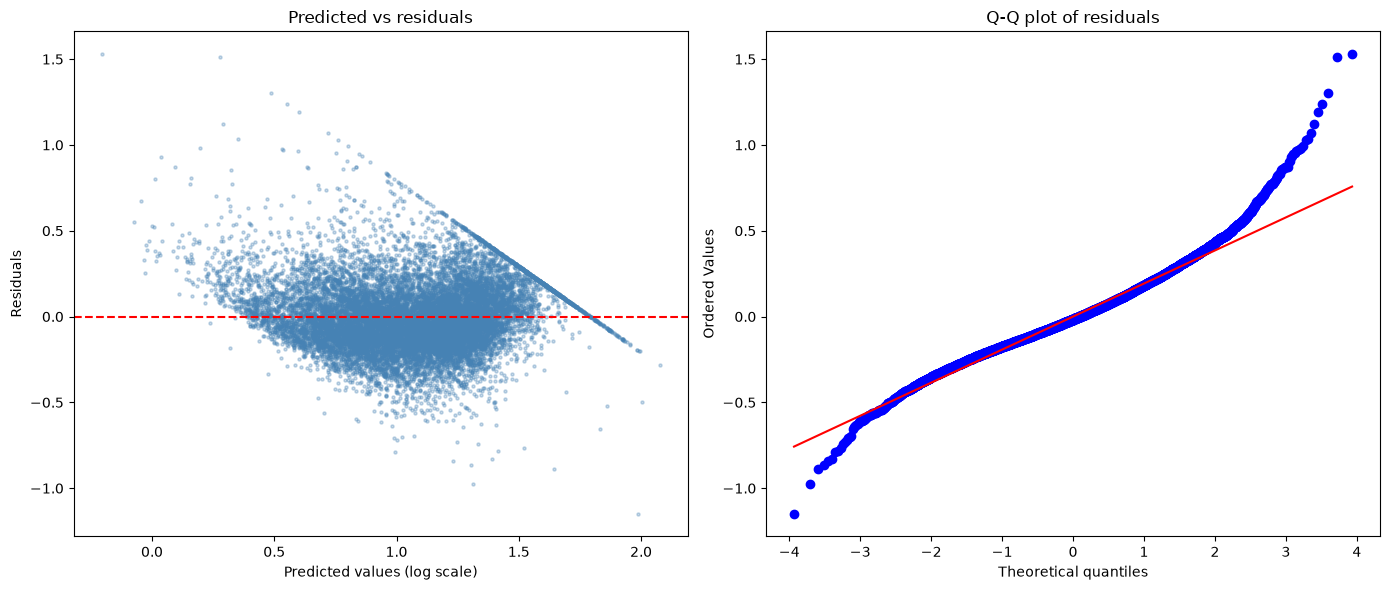

In [11]:
residuals = y_train_log - model.predict(X_train_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(model.predict(X_train_scaled), residuals, alpha=0.3, s=5, color="steelblue")
axes[0].axhline(y=0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted values (log scale)")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Predicted vs residuals")

stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot of residuals")

plt.tight_layout()
plt.savefig("figures/residual_diagnostics.png", dpi=150)
plt.show()

* Residuals are centred on zero with no strong systematic pattern, but their spread changes with the predicted
  value (a fan/triangle shape) – **homoscedasticity does not hold**. The diagonal edge on the right reflects the
  \$500k cap on the target.
* The Q-Q plot follows the normal line in the middle but has **heavy tails**, so residuals are not fully normal.
* Consequence: point predictions remain usable, but standard errors and confidence intervals from this OLS model
  would be unreliable without robust standard errors.

## 7. Ablation: do the transformations and features help?

In [12]:
# (a) Without geographic features
_, _, no_geo_metrics = fit_and_evaluate(
    X_train.drop(columns=GEO_FEATURES), X_test.drop(columns=GEO_FEATURES), "Without geographic features"
)

# (b) Without the log transform on the skewed features (target still in logs)
X_train_raw = X_train.copy()
X_test_raw = X_test.copy()
X_train_raw[high_skew_features] = np.expm1(X_train[high_skew_features])
X_test_raw[high_skew_features] = np.expm1(X_test[high_skew_features])
_, _, no_log_metrics = fit_and_evaluate(X_train_raw, X_test_raw, "Without log-transformed features")

comparison = pd.DataFrame([full_metrics, no_geo_metrics, no_log_metrics]).set_index("model").round(4)
comparison.to_csv("figures/model_comparison.csv")
comparison

,train_rmse,test_rmse,train_r2,test_r2
model,,,,
Full model,0.6449,0.6567,0.6889,0.6709
Without geographic features,0.6625,0.6727,0.6717,0.6546
Without log-transformed features,0.6965,0.7005,0.6371,0.6255


* **Geography matters:** dropping the three distance features raises test RMSE and lowers test R².
* **Log transforms help:** reverting the skewed features to their raw scale worsens both metrics.
* The full model explains roughly two-thirds of the variance in house values on unseen data.